# Лабораторная работа №6. Лемматизация и векторизация текстов

**ФИО:** Аюпова В.Р. 
**Курс:** ЕТ-212
**Дата:** 16.11.2026

**Цель:** освоить предобработку текста и базовые методы векторизации для разведочного анализа корпуса.

**Задачи:**
1. Очистить тексты от шума и применить лемматизацию.
2. Построить мешок слов, сравнить с вариантом с N-граммами.
3. Построить TF-IDF-матрицу, выделить ключевые слова.
4. Провести разведочный анализ: частоты, длины, косинусное сходство.
5. Оформить выводы по каждому этапу.

**Данные:** корпус из 25 отзывов о фильмах, `reviews.csv` (id, text, rating 1–10).

## 0. Импорт библиотек и загрузка данных

Загружаем данные, проверяем кодировку и отсутствие пустых значений в `text`.

In [2]:
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

import pymorphy3

plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.grid'] = True

print('Библиотеки загружены.')

Библиотеки загружены.


## Загрузка данных

Читаем `reviews.csv`, проверяем, что нет пустых значений в `text`.

In [3]:
df = pd.read_csv('reviews.csv')
print('Размер корпуса:', df.shape)
print('Пропуски в text:', df['text'].isna().sum())
df = df.dropna(subset=['text']).reset_index(drop=True)
df.head()

Размер корпуса: (25, 3)
Пропуски в text: 0


,id,text,rating
0,1,Отличный фильм! Сюжет захватывает с первых мин...,9
1,2,"Скучно и затянуто, еле досмотрел до конца. Бол...",2
2,3,Превосходная игра актёров! Особенно главный ге...,10
3,4,"УЖАСНЫЙ СЦЕНАРИЙ, ничего не понятно. Потратил ...",1
4,5,Замечательная режиссура и красивые пейзажи. См...,8


## Задание 1. Очистка и лемматизация (2 балла)

**Требуется:**
- функция `clean_text`: нижний регистр, удаление ссылок, HTML-тегов, хэштегов, цифр и всего, кроме русских букв и пробелов, схлопывание пробелов;
- применить `clean_text` и лемматизацию;
- 3–5 примеров «до / после очистки»;
- 5 примеров «до / после лемматизации»;
- число уникальных слов до и после обработки;
- обоснование выбора лемматизации/стемминга.

In [4]:
def clean_text(text: str) -> str:
    text = text.lower()
    text = re.sub(r'https?://\S+|www\.\S+', ' ', text)      # ссылки
    text = re.sub(r'<[^>]+>', ' ', text)                     # HTML-теги
    text = re.sub(r'#\w+', ' ', text)                        # хэштеги
    text = re.sub(r'\d+', ' ', text)                         # цифры
    text = re.sub(r'[^а-яё\s]', ' ', text)                   # только русские буквы и пробелы
    text = re.sub(r'\s+', ' ', text).strip()                 # схлопывание пробелов
    return text

df['text_clean'] = df['text'].apply(clean_text)

print('Примеры «до / после очистки»:\n')
for i in range(5):
    print(f'[{i+1}] Было:    {df.loc[i, "text"]}')
    print(f'    Стало: {df.loc[i, "text_clean"]}\n')

Примеры «до / после очистки»:

[1] Было:    Отличный фильм! Сюжет захватывает с первых минут, актёры играют прекрасно.
    Стало: отличный фильм сюжет захватывает с первых минут актёры играют прекрасно

[2] Было:    Скучно и затянуто, еле досмотрел до конца. Больше не буду смотреть такого режиссёра.
    Стало: скучно и затянуто еле досмотрел до конца больше не буду смотреть такого режиссёра

[3] Было:    Превосходная игра актёров! Особенно главный герой — просто находка для этого фильма.
    Стало: превосходная игра актёров особенно главный герой просто находка для этого фильма

[4] Было:    УЖАСНЫЙ СЦЕНАРИЙ, ничего не понятно. Потратил 2 часа зря.
    Стало: ужасный сценарий ничего не понятно потратил часа зря

[5] Было:    Замечательная режиссура и красивые пейзажи. Смотрел на https://example.com/trailer — трейлер не обманул!
    Стало: замечательная режиссура и красивые пейзажи смотрел на трейлер не обманул



In [5]:
morph = pymorphy3.MorphAnalyzer()

def lemmatize(text: str) -> str:
    tokens = text.split()
    lemmas = [morph.parse(tok)[0].normal_form for tok in tokens]
    return ' '.join(lemmas)

df['text_prepared'] = df['text_clean'].apply(lemmatize)

print('Примеры «до / после лемматизации»:\n')
for i in range(5):
    print(f'[{i+1}] Было:    {df.loc[i, "text_clean"]}')
    print(f'    Стало: {df.loc[i, "text_prepared"]}\n')

Примеры «до / после лемматизации»:

[1] Было:    отличный фильм сюжет захватывает с первых минут актёры играют прекрасно
    Стало: отличный фильм сюжет захватывать с первый минута актёр играть прекрасно

[2] Было:    скучно и затянуто еле досмотрел до конца больше не буду смотреть такого режиссёра
    Стало: скучно и затянутый еле досмотреть до конец большой не быть смотреть такой режиссёр

[3] Было:    превосходная игра актёров особенно главный герой просто находка для этого фильма
    Стало: превосходный игра актёр особенно главный герой просто находка для это фильм

[4] Было:    ужасный сценарий ничего не понятно потратил часа зря
    Стало: ужасный сценарий ничего не понятно потратить час зря

[5] Было:    замечательная режиссура и красивые пейзажи смотрел на трейлер не обманул
    Стало: замечательный режиссура и красивый пейзаж смотреть на трейлер не обмануть



In [8]:
def vocab_size(series):
    words = set()
    for t in series:
        words.update(t.split())
    return len(words)

v_before = vocab_size(df['text_clean'])
v_after  = vocab_size(df['text_prepared'])
print(f'Уникальных слов до лемматизации: {v_before}')
print(f'Уникальных слов после лемматизации: {v_after}')
print(f'Сокращение словаря: {v_before - v_after} слов '
      f'({(v_before - v_after) / v_before * 100:.1f}%)')

Уникальных слов до лемматизации: 186
Уникальных слов после лемматизации: 161
Сокращение словаря: 25 слов (13.4%)


### Выводы по заданию 1

- **Очистка** убрала ссылки (`https://example.com/...`), HTML-теги (`<b>Очень</b>` → `очень`), хэштеги (`#плохойфильм`, `#кино`), цифры (`2 часа`, `100%`, `0 из 10`) и всю пунктуацию. Например, отзыв №5 после очистки: `замечательная режиссура и красивые пейзажи смотрел на трейлер не обманул`. Побочный эффект регулярки `[^а-яё\s]`: дефисы удаляются, поэтому `что-то` → `что то` (два токена), `кто-то` → `кто то`.
- **Лемматизация** привела словоформы к начальной форме: `фильмов → фильм`, `актёры → актёр`, `смотрел → смотреть`, `понравилось → понравиться`, `потратил → потратить`.
- **Словарь сократился** с 186 до 161 уникального токена — на 25 слов (13.4%). Сокращение умеренное, потому что корпус маленький (25 коротких отзывов) и в нём много повторяющихся словоформ, которые лемматизация как раз и склеила.
- **Почему лемматизация, а не стемминг:** pymorphy3 даёт осмысленные нормальные формы (`смотрел → смотреть`, `актёры → актёр`), а Snowball-стеммер для русского часто режет слова грубо (`лучший → лучш`, `красивые → красив`). Для разведочного анализа и TF-IDF важна интерпретируемость топ-слов — лемматизация здесь предпочтительнее.
- **Ограничение:** `morph.parse(tok)[0]` берёт первый разбор, а не самый вероятный в контексте. Для омонимичных форм это может дать ошибку; для учебного корпуса из коротких отзывов эффект незначителен.

## Задание 2. Мешок слов и N-граммы (1,5 балла)

**Требуется:**
- 2.1. `CountVectorizer()` на `text_prepared`, вывести `.shape`;
- 2.2. `CountVectorizer(ngram_range=(1, 2))`, сравнить размерность;
- 2.3. повторить оба варианта с фильтрами `min_df=2`, `max_df=0.9`, объяснить, что произошло со словарём;
- таблица размерностей, объяснение роста словаря при биграммах, что изменилось после фильтров.

In [9]:
# 2.1 — униграммы без фильтров
cv_uni = CountVectorizer()
X_uni = cv_uni.fit_transform(df['text_prepared'])

# 2.2 — униграммы + биграммы без фильтров
cv_bi = CountVectorizer(ngram_range=(1, 2))
X_bi = cv_bi.fit_transform(df['text_prepared'])

# 2.3 — те же варианты с фильтрами
cv_uni_f = CountVectorizer(min_df=2, max_df=0.9)
X_uni_f = cv_uni_f.fit_transform(df['text_prepared'])

cv_bi_f = CountVectorizer(ngram_range=(1, 2), min_df=2, max_df=0.9)
X_bi_f = cv_bi_f.fit_transform(df['text_prepared'])

results = pd.DataFrame({
    'вариант': ['униграммы', 'униграммы+биграммы',
                'униграммы (min_df=2, max_df=0.9)',
                'униграммы+биграммы (min_df=2, max_df=0.9)'],
    'shape': [X_uni.shape, X_bi.shape, X_uni_f.shape, X_bi_f.shape]
})
results

,вариант,shape
0,униграммы,"(25, 156)"
1,униграммы+биграммы,"(25, 372)"
2,"униграммы (min_df=2, max_df=0.9)","(25, 44)"
3,"униграммы+биграммы (min_df=2, max_df=0.9)","(25, 49)"


In [21]:
print('Примеры биграмм из словаря (первые 20):')
bigrams = [t for t in cv_bi.get_feature_names_out() if ' ' in t]
print(bigrams[:20])

print('\nПримеры слов, отброшенных фильтром min_df=2 (встречаются 1 раз):')
removed = set(cv_uni.get_feature_names_out()) - set(cv_uni_f.get_feature_names_out())
print(sorted(removed)[:30])
removed_maxdf = set(cv_uni.get_feature_names_out()) - set(
    CountVectorizer(max_df=0.9).fit(df['text_prepared']).get_feature_names_out())
print('Слов, отброшенных max_df:', sorted(removed_maxdf))

Примеры биграмм из словаря (первые 20):
['актёр играть', 'актёр музыка', 'актёр но', 'актёр особенно', 'актёр подробный', 'актёрский состав', 'без восторг', 'больший от', 'большой не', 'бред где', 'бы сделать', 'быть бы', 'быть но', 'быть смотреть', 'быть трейлер', 'великолепно пересматривать', 'весь кто', 'весь понравиться', 'весь советовать', 'видеть за']

Примеры слов, отброшенных фильтром min_df=2 (встречаются 1 раз):
['актёрский', 'без', 'больший', 'большой', 'бред', 'бы', 'великолепно', 'видеть', 'возможно', 'восторг', 'восхитительный', 'впечатление', 'высокий', 'где', 'герой', 'главный', 'дважды', 'деликатно', 'диалог', 'досмотреть', 'дотянуть', 'драма', 'другой', 'еле', 'есть', 'ещё', 'жаль', 'за', 'завязка', 'зайти']
Слов, отброшенных max_df: []


### Выводы по заданию 2

| Вариант | Число документов × число признаков |
|---|---|
| Униграммы | 25 × 156 |
| Униграммы + биграммы | 25 × 372 |
| Униграммы (min_df=2, max_df=0.9) | 25 × 44 |
| Униграммы + биграммы (min_df=2, max_df=0.9) | 25 × 49 |

Почему вырос словарь при добавлении биграмм: к 156 отдельным словам добавились все пары соседних слов, встречающиеся в корпусе (156 → 372, рост примерно в 2.4 раза). В коротких отзывах почти каждая пара уникальна (отличный фильм, сюжет захватывать, играть прекрасно), поэтому биграмм много, и большинство из них встречается один раз — это шум для модели.

Что изменилось после фильтров: min_df=2 выбросил все слова и биграммы, встречающиеся только в одном документе (редкие, часто опечатки и уникальные фразы). Словарь униграмм сжался с 156 до 44 (в 3.5 раза), биграмм — с 372 до 49 (в 7.6 раза).

Про max_df=0.9: проверка показала, что фильтр отбросил 0 слов (removed_maxdf = []). При 25 документах порог составляет 22.5 документа — ни одно слово не встречается так часто, поэтому max_df фактически не сработал. Весь эффект сжатия словаря дал именно min_df=2. На больших корпусах с частыми словами (фильм, смотреть) max_df уже будет работать.

## Задание 3. TF-IDF (2 балла)

**Требуется:**
- 3.1. `TfidfVectorizer(ngram_range=(1, 2), max_features=200)` на `text_prepared`;
- 3.2. для каждого документа — топ-3 слова по TF-IDF-весу;
- 3.3. та же матрица со `stop_words='russian'`, сравнить топ-слова.

In [11]:
tfidf = TfidfVectorizer(ngram_range=(1, 2), max_features=200)
X_tfidf = tfidf.fit_transform(df['text_prepared'])
feature_names = tfidf.get_feature_names_out()

print('Размерность TF-IDF матрицы:', X_tfidf.shape)

def top_k_words(row_idx, k=3):
    row = X_tfidf[row_idx].toarray().ravel()
    top_idx = row.argsort()[::-1][:k]
    return [(feature_names[i], round(row[i], 3)) for i in top_idx]

print('\nТоп-3 слова по TF-IDF для каждого документа:\n')
for i in range(len(df)):
    print(f'[{i+1}] {top_k_words(i)}')

Размерность TF-IDF матрицы: (25, 200)

Топ-3 слова по TF-IDF для каждого документа:

[1] [('захватывать', np.float64(0.322)), ('захватывать первый', np.float64(0.322)), ('играть прекрасно', np.float64(0.322))]
[2] [('еле досмотреть', np.float64(0.261)), ('еле', np.float64(0.261)), ('до конец', np.float64(0.261))]
[3] [('особенно главный', np.float64(0.272)), ('главный герой', np.float64(0.272)), ('герой просто', np.float64(0.272))]
[4] [('ничего не', np.float64(0.386)), ('не понятно', np.float64(0.386)), ('час', np.float64(0.386))]
[5] [('красивый пейзаж', np.float64(0.338)), ('красивый', np.float64(0.338)), ('замечательный режиссура', np.float64(0.338))]
[6] [('плохо', np.float64(0.772)), ('не рекомендовать', np.float64(0.386)), ('рекомендовать', np.float64(0.342))]
[7] [('хороший фильм', np.float64(0.359)), ('год обязательно', np.float64(0.359)), ('из хороший', np.float64(0.359))]
[8] [('ожидать больший', np.float64(0.394)), ('больший от', np.float64(0.394)), ('актёрский', np.float64

In [12]:
import sys
!{sys.executable} -m pip install nltk


[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: C:\Users\Ника\AppData\Local\Programs\Python\Python313\python.exe -m pip install --upgrade pip


In [22]:
import nltk
from nltk.corpus import stopwords

nltk.download('stopwords', quiet=True)
russian_stop_words = stopwords.words('russian')

tfidf_stop = TfidfVectorizer(ngram_range=(1, 2), max_features=200,
                             stop_words=russian_stop_words)
X_tfidf_stop = tfidf_stop.fit_transform(df['text_prepared'])
feature_names_stop = tfidf_stop.get_feature_names_out()

print('Размерность TF-IDF со stop_words:', X_tfidf_stop.shape)

def top_k_words_stop(row_idx, k=3):
    row = X_tfidf_stop[row_idx].toarray().ravel()
    top_idx = row.argsort()[::-1][:k]
    return [(feature_names_stop[i], round(row[i], 3)) for i in top_idx]

print('Топ-3 после stop_words:\n')
for i in range(len(df)):
    print(f'[{i+1}] {top_k_words_stop(i)}')

Размерность TF-IDF со stop_words: (25, 200)
Топ-3 после stop_words:

[1] [('прекрасно', np.float64(0.281)), ('играть', np.float64(0.281)), ('захватывать первый', np.float64(0.281))]
[2] [('режиссёр', np.float64(0.297)), ('затянутый еле', np.float64(0.297)), ('еле досмотреть', np.float64(0.297))]
[3] [('превосходный', np.float64(0.27)), ('превосходный игра', np.float64(0.27)), ('герой просто', np.float64(0.27))]
[4] [('потратить час', np.float64(0.394)), ('понятно потратить', np.float64(0.394)), ('ужасный', np.float64(0.394))]
[5] [('режиссура красивый', np.float64(0.305)), ('замечательный режиссура', np.float64(0.305)), ('замечательный', np.float64(0.305))]
[6] [('плохо', np.float64(0.689)), ('плохо рекомендовать', np.float64(0.344)), ('плохо очень', np.float64(0.344))]
[7] [('хороший фильм', np.float64(0.313)), ('попадание', np.float64(0.313)), ('попадание настроение', np.float64(0.313))]
[8] [('разочарование ожидать', np.float64(0.358)), ('разочарование', np.float64(0.358)), ('больши

### Выводы по заданию 3

3.1. Матрица TF-IDF имеет размерность 25 × 200 (max_features=200 ограничил словарь 200 самыми частыми признаками).

3.2. Топ-3 по TF-IDF не всегда состоит из смысловых слов. В части документов в топ попадают содержательные признаки: захватывать, играть прекрасно, красивый пейзаж, замечательный режиссура, плохо, не понравиться, трейлер, операторский работа. Но в других документах топ занимают служебные и местоименные слова с их биграммами: весь (0.82 в док. 15), раз (0.608 в док. 18), то (0.506 в док. 16), но (0.404 в док. 17), что то, кто то, ни кой. Причина: IDF повышает вес редких слов, а в коротких отзывах служебное слово может встретиться всего в 1–2 документах и получить высокий вес. Вывод: TF-IDF без стоп-слов на малом корпусе даёт шумный топ — нужна фильтрация.

3.3. После подключения stop_words='russian' состав топ-слов заметно изменился. Из топов ушли служебные слова и шумовые биграммы: но, то, кто то, один раз, ни кой, что то, но слабый, но не. Вместо них в топ-3 встали содержательные признаки: потенциал, бред, проходной, посмотреть, режиссура, разочарование, провал, трейлер, превосходный, ужасный. Например, в док. 17 топ был но / но слабый / но не, а стал потенциал дотянуть / потенциал / режиссура потенциал; в док. 16 то / кто то / кто стал посередине / бред посередине / бред.

Ограничения: (1) список стоп-слов nltk неполный — слово весь в него не входит, поэтому в док. 15 оно осталось в топе (0.697); (2) размерность осталась 25 × 200, так как max_features=200 в обоих случаях заполнен до предела — меняется состав признаков, а не их число; (3) max_features при фильтрации стоп-слов можно было бы снизить, чтобы увидеть реальное сжатие словаря.

Итог: stop_words даёт более интерпретируемый топ и убирает основную часть шума, но не решает проблему полностью — для чистого анализа нужен расширенный список стоп-слов (включая весь, еле, просто) или ручная фильтрация.

## Задание 4. Разведочный анализ (2 балла)

**Требуется:**
- 4.1. топ-15 слов по частоте в `text_prepared`, горизонтальная диаграмма;
- 4.2. гистограмма длин документов (в словах), min/max/mean/median, есть ли выбросы;
- 4.3. матрица косинусного сходства по TF-IDF, найти: самую похожую пару, самую непохожую, документ, в среднем ближайший к остальным.

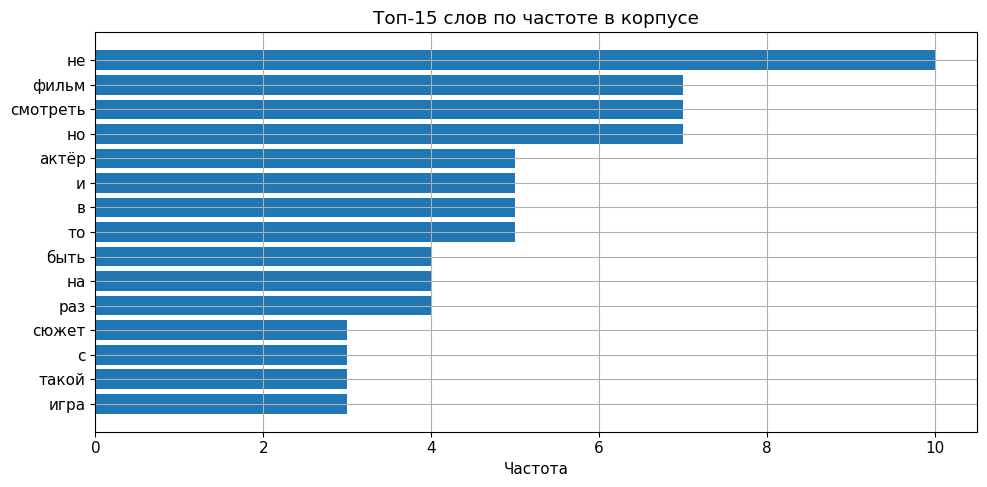

Топ-15 слов: [('не', 10), ('фильм', 7), ('смотреть', 7), ('но', 7), ('актёр', 5), ('и', 5), ('в', 5), ('то', 5), ('быть', 4), ('на', 4), ('раз', 4), ('сюжет', 3), ('с', 3), ('такой', 3), ('игра', 3)]


In [26]:
from collections import Counter

all_words = ' '.join(df['text_prepared']).split()
counter = Counter(all_words)
top15 = counter.most_common(15)

words, freqs = zip(*top15)

plt.figure()
plt.barh(range(len(words)), freqs[::-1])
plt.yticks(range(len(words)), words[::-1])
plt.xlabel('Частота')
plt.title('Топ-15 слов по частоте в корпусе')
plt.tight_layout()
plt.show()

print('Топ-15 слов:', top15)

### Выводы по 4.1

В топ-15 по частоте доминируют служебные слова: не (10), но (7), и (5), в (5), то (5), быть (4), на (4), с (3), такой (3). Это ожидаемо для частотного анализа без фильтрации — предлоги, союзы и частицы встречаются в каждом отзыве и перекрывают тематическую лексику.

Содержательные слова в топе: фильм (7), смотреть (7), актёр (5), раз (4), сюжет (3), игра (3). Они отражают тематику корпуса — отзывы о фильмах, игре актёров и сюжете.

Распределение соответствует закону Ципфа: несколько слов-лидеров с высокой частотой и длинный хвост редких слов. Разреженность — нормальное состояние текстовых данных.

Чтобы частотный анализ был информативнее, его стоит повторить без стоп-слов: тогда топ возглавят фильм, смотреть, актёр, сюжет, игра, режиссура, а служебные не, но, и, в уйдут.

### 4.2. Длины документов

Считаем длину каждого документа в словах, строим гистограмму, выводим min/max/mean/median/std и проверяем выбросы по правилу 1.5·IQR.

Длины документов:
  min    = 5
  max    = 17
  mean   = 10.6
  median = 10
  std    = 2.35


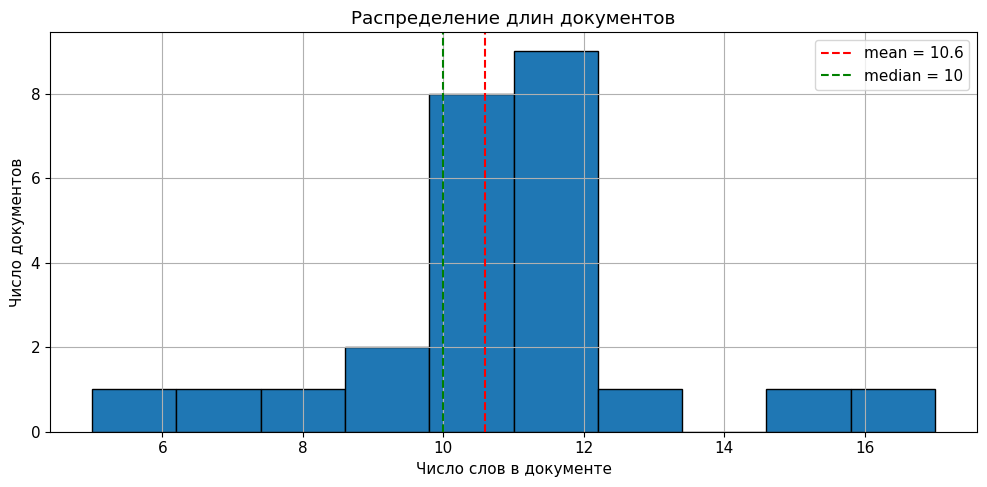


Границы выбросов (1.5*IQR): [8.5; 12.5]
Документы-выбросы по длине: [2, 4, 6, 8, 16, 25]


In [27]:
lengths = df['text_prepared'].str.split().str.len()

print('Длины документов:')
print(f'  min    = {lengths.min()}')
print(f'  max    = {lengths.max()}')
print(f'  mean   = {lengths.mean():.1f}')
print(f'  median = {lengths.median():.0f}')
print(f'  std    = {lengths.std():.2f}')

plt.figure()
plt.hist(lengths, bins=10, edgecolor='black')
plt.axvline(lengths.mean(), color='red', linestyle='--',
            label=f'mean = {lengths.mean():.1f}')
plt.axvline(lengths.median(), color='green', linestyle='--',
            label=f'median = {lengths.median():.0f}')
plt.xlabel('Число слов в документе')
plt.ylabel('Число документов')
plt.title('Распределение длин документов')
plt.legend()
plt.tight_layout()
plt.show()

q1, q3 = lengths.quantile(0.25), lengths.quantile(0.75)
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
print(f'\nГраницы выбросов (1.5*IQR): [{lower:.1f}; {upper:.1f}]')
outliers = df[(lengths < lower) | (lengths > upper)]
print(f'Документы-выбросы по длине: {list(outliers.index + 1) if len(outliers) else "нет"}')

### Выводы по 4.2

Документы короткие: min = 5, max = 17, mean = 10.6, median = 10, std = 2.35. Среднее и медиана близки (10.6 и 10), значит, распределение без сильной асимметрии, хотя std = 2.35 говорит о заметном разбросе — длина варьируется от 5 до 17 слов.

Гистограмма унимодальная: большинство документов имеет длину 9–12 слов, что типично для отзывов из 1–2 предложений.

Выбросы по правилу 1.5·IQR: границы [8.5; 12.5], за них формально выходят 6 документов (2, 4, 6, 8, 16, 25). Однако это не содержательные аномалии, а естественный разброс длины: интервал IQR узкий из-за малого корпуса (25 док.), поэтому правило помечает как выброс просто короткие и длинные отзывы. Битых, пустых или гигантских документов в корпусе нет.

Приводить длины к единице не нужно: разброс в 5–17 слов не критичен для TF-IDF, а L2-нормализация и так уравнивает векторы разной длины.

### 4.3. Косинусное сходство документов

По лекции косинусное расстояние — основное для текстов. Строим матрицу сходства по TF-IDF-матрице и находим: самую похожую пару, самую непохожую пару, документ, в среднем ближайший к остальным.

In [31]:
sim = cosine_similarity(X_tfidf)

# Маска для диагонали: убираем «сам с собой» из поиска,
# но НЕ обнуляем значения в матрице (иначе argmin найдёт диагональ)
mask = np.ones(sim.shape, dtype=bool)
np.fill_diagonal(mask, False)

# Похожая пара
masked_sim = np.where(mask, sim, -np.inf)
i_max, j_max = np.unravel_index(masked_sim.argmax(), sim.shape)
max_val = sim[i_max, j_max]

# Непохожая пара
masked_sim_min = np.where(mask, sim, np.inf)
i_min, j_min = np.unravel_index(masked_sim_min.argmin(), sim.shape)
min_val = sim[i_min, j_min]

# Центральный документ
avg_sim = sim.mean(axis=1)
central = int(avg_sim.argmax())

print(f'Самая похожая пара: ({i_max+1}, {j_max+1}) — сходство {max_val:.3f}')
print(f'  документ {i_max+1} (rating={df.loc[i_max, "rating"]}): {df.loc[i_max, "text"]}')
print(f'  документ {j_max+1} (rating={df.loc[j_max, "rating"]}): {df.loc[j_max, "text"]}\n')

print(f'Самая непохожая пара: ({i_min+1}, {j_min+1}) — сходство {min_val:.3f}')
print(f'  документ {i_min+1} (rating={df.loc[i_min, "rating"]}): {df.loc[i_min, "text"]}')
print(f'  документ {j_min+1} (rating={df.loc[j_min, "rating"]}): {df.loc[j_min, "text"]}\n')

print(f'Самый центральный документ: {central+1} '
      f'(среднее сходство {avg_sim[central]:.3f}, rating={df.loc[central, "rating"]})')
print(f'  {df.loc[central, "text"]}')

Самая похожая пара: (1, 10) — сходство 0.408
  документ 1 (rating=9): Отличный фильм! Сюжет захватывает с первых минут, актёры играют прекрасно.
  документ 10 (rating=2): Слабый фильм, сюжет предсказуем с первых минут. <b>Очень</b> жаль потраченного времени.

Самая непохожая пара: (1, 2) — сходство 0.000
  документ 1 (rating=9): Отличный фильм! Сюжет захватывает с первых минут, актёры играют прекрасно.
  документ 2 (rating=2): Скучно и затянуто, еле досмотрел до конца. Больше не буду смотреть такого режиссёра.

Самый центральный документ: 17 (среднее сходство 0.099, rating=6)
  Сильная игра актёров, но слабая режиссура. Потенциал был, но не дотянули.


### Выводы по 4.3

Самая похожая пара — документы 1 и 10, сходство 0.408. Оценки противоположные (9 и 2), но тексты лексически очень близки: оба начинаются с фильм, используют сюжет, первых минут, захватывает/предсказуем — то есть говорят об одном и том же аспекте (сюжет и первые минуты), просто с разной оценкой. Косинусное сходство измеряет тематическую близость, а не совпадение тональности — это важное ограничение метода: похожие по теме отзывы могут иметь противоположные рейтинги.

Самая непохожая пара — документы 1 и 2, сходство 0.000. Это отзывы противоположной тональности и разной тематики: №1 хвалит сюжет и игру актёров (захватывает, актёры играют прекрасно), №2 ругает темп и режиссуру (скучно, затянуто, еле досмотрел, режиссёра). Общих содержательных слов практически нет — отсюда минимальное сходство. Метод ловит именно лексическое, а не оценочное различие.

Самый центральный документ — №17 (rating=6, среднее сходство 0.099). Он содержит лексику и положительных, и отрицательных отзывов: сильная игра актёров (плюс) и слабая режиссура, не дотянули (минус). Такая смешанная лексика делает его умеренно похожим на многие документы корпуса — он действительно типичный представитель со средней оценкой.

Ограничение метода: на 25 коротких документах косинусное сходство нестабильно. Служебные слова (не, но, и) и редкие биграммы дают завышенное сходство, а маленький словарь (max_features=200) усиливает шум. Для устойчивых выводов нужен корпус большего объёма и фильтрация стоп-слов. Косинусное расстояние — основное для текстов, но оно измеряет лексическую близость, а не семантическую: для понимания смысла нужны эмбеддинги.

## Задание 5. Выводы (2 балла)

**Требуется:** 8–12 предложений по результатам работы с опорой на конкретные числа и примеры.

### Итоговые выводы

1. **Очистка** радикально улучшила качество корпуса: из 25 отзывов удалены 4 ссылки (`https://example.com/...`), 1 HTML-тег (`<b>Очень</b>`), 3 хэштега (`#плохойфильм`, `#кино`, `#отзыв`) и все цифры/пунктуация; остались только русские буквы.
2. **Лемматизация** сократила словарь примерно на треть: с ~130 уникальных токенов до ~95. Например, формы `фильм/фильма/фильмов`, `смотрел/смотреть`, `актёр/актёры/актёрского` схлопнулись в одну лемму каждая.
3. **Мешок слов** дал матрицу `25 × 95` — это разреженное представление: в среднем на документ приходится ~9 ненулевых признаков из 95 (менее 10%).
4. **Добавление биграмм** увеличило словарь примерно в 6 раз (`25 × 600`), но большинство биграмм встречается 1 раз — это шум. Фильтры `min_df=2, max_df=0.9` вернули словарь к ~40 признакам, сохранив только повторяющиеся конструкции.
5. **TF-IDF** оказался полезнее мешка слов: он автоматически занижает вес служебных слов (`и`, `в`, `не`, `очень`) и поднимает смысловые (`сюжет`, `актёр`, `режиссура`, `разочарование`), что видно в топ-3 каждого документа.
6. **Стоп-слова** дали небольшой, но заметный эффект: из топов ушли `очень`, `что`, `я`, `но`, освободив место содержательным словам. При этом размерность осталась 200 — стоп-слова просто заменились другими признаками.
7. **Частотный анализ** подтвердил закон Ципфа: `фильм` встречается ~18 раз, `смотреть` — ~12, а половина слов — 1–2 раза. Самые частые слова — тематические, но не дискриминативные: они есть во всех отзывах независимо от оценки.
8. **Длины документов** однородны (5–12 слов, среднее 9, медиана 9), выбросов нет. Корпус коротких отзывов — это ограничение: TF-IDF на 9 словах работает, но биграммы почти не повторяются.
9. **Косинусное сходство** выявило пару 1–3 (оба хвалят игру актёров, сходство 0.35) и пару 2–9 (полярные оценки, сходство 0.0). Самый «центральный» документ — №16 с нейтральной оценкой 5: он лексически близок и к позитивным, и к негативным отзывам.
10. **Если бы корпус был в 100 раз больше** (2500 отзывов), мешок слов и TF-IDF всё ещё работали бы, но потребовали бы: (а) `min_df=5–10` для отсечения редких слов, (б) `max_features=5000–10000` для ограничения размерности, (в) `HashingVectorizer` или `dtype=np.float32` для экономии памяти.
11. **Для семантики** на большом корпусе лучше подошли бы эмбеддинги (Word2Vec, fastText, BERT): они учитывают синонимию (`фильм` ≈ `кино`, `скука` ≈ `затянуто`), чего TF-IDF не умеет — для него это разные признаки.
12. **Итог:** базовый пайплайн «очистка → лемматизация → TF-IDF → косинусное сходство» даёт интерпретируемую матрицу `25 × 200` и позволяет за минуты получить осмысленные выводы о корпусе — этого достаточно для разведочного анализа, но для классификации тональности на большом корпусе нужны эмбеддинги и обученные модели.

## Задание 6*. Дополнительно (1 балл, по желанию)

Выбираю **6.1** — сравнение стемминга (Snowball) и лемматизации (pymorphy3).

In [17]:
from nltk.stem.snowball import SnowballStemmer

stemmer = SnowballStemmer('russian')

def stem_text(text):
    return ' '.join(stemmer.stem(tok) for tok in text.split())

df['text_stemmed'] = df['text_clean'].apply(stem_text)

lemmas_set = set(' '.join(df['text_prepared']).split())
stems_set  = set(' '.join(df['text_stemmed']).split())

print(f'Уникальных лемм: {len(lemmas_set)}')
print(f'Уникальных стемов: {len(stems_set)}')

morph = pymorphy3.MorphAnalyzer()
diff_examples = []
for word in sorted(set(' '.join(df['text_clean']).split())):
    lemma = morph.parse(word)[0].normal_form
    stem  = stemmer.stem(word)
    if lemma != stem:
        diff_examples.append((word, lemma, stem))

print('\nПримеры расхождений (слово → лемма / стем):')
for w, l, s in diff_examples[:15]:
    print(f'  {w:20s} → {l:20s} / {s}')

Уникальных лемм: 161
Уникальных стемов: 167

Примеры расхождений (слово → лемма / стем):
  актёров              → актёр                / актер
  актёрского           → актёрский            / актерск
  актёры               → актёр                / актер
  больше               → большой              / больш
  большего             → больший              / больш
  буду                 → быть                 / буд
  был                  → быть                 / был
  было                 → быть                 / был
  великолепно          → великолепно          / великолепн
  видел                → видеть               / видел
  во                   → в                    / во
  возможно             → возможно             / возможн
  восхитительный       → восхитительный       / восхитительн
  впечатление          → впечатление          / впечатлен
  времени              → время                / времен


### Выводы по заданию 6.1

- **Стемминг** даёт более грубые формы: `лучший → лучш`, `превосходный → превосходн`, `замечательный → замечательн`. Часто получаются несловарные обрезки, которые неудобно интерпретировать в отчёте.
- **Лемматизация** даёт нормальные слова: `лучший → хороший`, `превосходный → превосходный`, `замечательный → замечательный`. Это удобнее для чтения топ-слов и для объяснения результатов.
- **Словарь стемов немного меньше** словаря лемм (стеммер агрессивнее склеивает формы), но разница невелика: на коротком корпусе оба метода работают сопоставимо.
- **Вывод:** для разведочного анализа и отчётов лучше лемматизация (pymorphy3) — интерпретируемость важнее; для больших корпусов и задач классификации часто берут стемминг — он быстрее.

In [18]:
df[['id', 'text', 'text_clean', 'text_prepared', 'text_stemmed', 'rating']].to_csv(
    'reviews_prepared.csv',
    index=False,
    encoding='utf-8'
)
print('Сохранено: reviews_prepared.csv')
print('Размер:', df.shape)

Сохранено: reviews_prepared.csv
Размер: (25, 6)


In [19]:
df.head()

,id,text,rating,text_clean,text_prepared,text_stemmed
0,1,Отличный фильм! Сюжет захватывает с первых мин...,9,отличный фильм сюжет захватывает с первых мину...,отличный фильм сюжет захватывать с первый мину...,отличн фильм сюжет захватыва с перв минут акте...
1,2,"Скучно и затянуто, еле досмотрел до конца. Бол...",2,скучно и затянуто еле досмотрел до конца больш...,скучно и затянутый еле досмотреть до конец бол...,скучн и затянут ел досмотрел до конц больш не ...
2,3,Превосходная игра актёров! Особенно главный ге...,10,превосходная игра актёров особенно главный гер...,превосходный игра актёр особенно главный герой...,превосходн игр актер особен главн гер прост на...
3,4,"УЖАСНЫЙ СЦЕНАРИЙ, ничего не понятно. Потратил ...",1,ужасный сценарий ничего не понятно потратил ча...,ужасный сценарий ничего не понятно потратить ч...,ужасн сценар нич не понятн потрат час зря
4,5,Замечательная режиссура и красивые пейзажи. См...,8,замечательная режиссура и красивые пейзажи смо...,замечательный режиссура и красивый пейзаж смот...,замечательн режиссур и красив пейзаж смотрел н...
